## Router

### Review

We built a graph that uses messages as state and chat model woth bound tools.

We saw that the graph can:
- Return a call.
- Return a natural language response.

### Goal

- We can think this as router, where the chat model routes between a direct response or a tool call based upon the user input.
- Let's extend the graph to work with either outout!
- For this idea, we can use two ideas:
    - Add a node that will call our tool
    - Add a conditional edge that will look at the chat model output, and route to our tool calling node or simply end if no tool call is performed 

### Define Tool

In [1]:
from langchain_ollama import ChatOllama
qwen = ChatOllama(model="qwen2.5:7b", temperature=0)

In [2]:
def multiply(a: int, b: int) -> int:
    """Multiply a and b
    Args:
        a: first int
        b: second int
    """

    return a * b

In [3]:
qween_bind_with_tool = qwen.bind_tools([multiply])

- We use the built-in [ToolNode](https://reference.langchain.com/python/langgraph.prebuilt/tool_node/ToolNode) and simply pass a list of our tools to initilaize it.
- We use built-in [tools_conditions](https://reference.langchain.com/python/langgraph.prebuilt/tool_node/tools_condition) as our conditional edge.

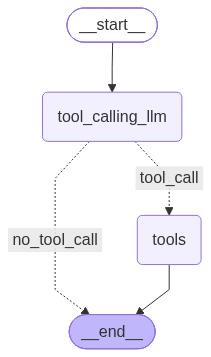

In [6]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition



# Node

def tool_calling_llm(state: MessagesState) -> str:
    return {"messages": [qween_bind_with_tool.invoke(state["messages"])]}




# Build the graph

builder = StateGraph(MessagesState)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools=[multiply]))
builder.add_edge(START, "tool_calling_llm")

builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message from assistant is a tool call -> tools_condition routes to tools
    # If the latest message from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
    {
        "tool_call": "tools",
        "no_tool_call": END
    }
)


builder.add_edge("tools", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))
